In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from joblib import Parallel, delayed
import fspiderman as sp
import batman
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from joblib.externals.loky import get_reusable_executor  # to recycle leaky SPIDERMAN workers
from HItargets_utils import *

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
# Target planet from the NASA Exoplanet Archive (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = planet.args

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from target data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
A_B = 3/2 * Ag # 0.42
# More physical would be:
# A_B = 0.1 # typical lava world in optical (Essack 2020), probably slight underestimate for bolometric.
# A_B = q * f_red * Ag_opt # with q~0.6 (more realistic for e.g. moon, Mercury), and f_red a spectral correction factor.

# ASSUMPTION (!)
# Model for band-integrated albedo in the observing band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate). Also, A_LRS and A_B are basically unrelated since >99% of stellar flux is below 5um - same actually goes for Spitzer: 98% under 3.7um.

In [4]:
# Filter to be used
instrument, instrument_pandexo = "JWST_NIRSpec.G395H_NRS1", "NIRSpec G395H"  # "MIRI/LRS", "MIRI LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

## Detectability and parameter bias analysis

The detection error per minute comes from PandExo for the planet and instrument set above (printed below). For comparison, K2-141b with MIRI/LRS 5.0-10.5 um has 323 ppm per minute.


In [5]:
n_bins = 27 # number of bins in one orbit
minutes_binning = period*24*60/n_bins # bin width [minutes] - approx. 15min
sigma_1min = rms_1min(run_pandexo(planet.name, instrument_pandexo, t14_h=planet.T14), planet.T14, filter_lambda(instrument))
n_orbits        = 3 # number of orbits observed (3 orbits has been done)


l1, l2 = lrs_range
stellar_grid = sp.stellar_grid.gen_grid(l1, l2, logg=4.5, response=lrs_path)

A_B_true = A_B  # 3/2 * Ag(Zieba2022) = 0.42;  under A = A_B this single albedo sets BOTH the reflected amplitude and the Bond albedo (dayside temperature)

# context for the bias-analysis functions imported from simple_bias_analysis.py (T_floor=200, bounds=(0.0, 0.6) by default)
cfg = FittingConfig(planet=planet, stellar_grid=stellar_grid, filter_path=lrs_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_B=u_B, u=u)


sigma_bin = cfg.sigma_bin # [ppm]
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

PandExo inputs for TOI-2431 b  [instrument=NIRSpec G395H]
    period     = 0.2242       d                <- pl_orbper
    rp_rearth  = 1.534        R_earth          <- pl_rade
    rs_rsun    = 0.651        R_sun            <- st_rad
    teff       = 4109         K                <- st_teff
    logg       = 4.68         log cgs          <- st_logg
    metal      = -0.02        log Fe/H         <- st_met
    t14_h      = 0.7475       h                <- override
    mag        = 7.554        mag (sy_kmag)    <- sy_kmag
    ref_wave   = 2.22         um               <- sy_kmag
    fixed: noccultations=1, sat_level=60%, baseline=1 (frac), R=None (native), noise_floor=0 ppm, ngroup=optimize, background=ecliptic/high

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
{'Group Number Too Low?': 'All good', 'Group Number Too High?': '

### 1. Pure Detectability

In [6]:
# Full phase curve (reflected + thermal). The naive curve uses full_PhaseCurve(insolation_model="naive")
t_k, pc_k, fp_k = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B)
t_n, pc_n, fp_n = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive", u_B=u_B)

# Transit removed (phase modulation + occultation only) = reflected(no transit) + thermal(no transit), so the modulation is visible
_, lc_k, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="hyperillum", u_B=u_B, include_transit=False)
_, lc_n, _ = full_PhaseCurve(planet, lrs_range, u=u, filter_path=lrs_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=300, n_la=150, insolation_model="naive",      u_B=u_B, include_transit=False)

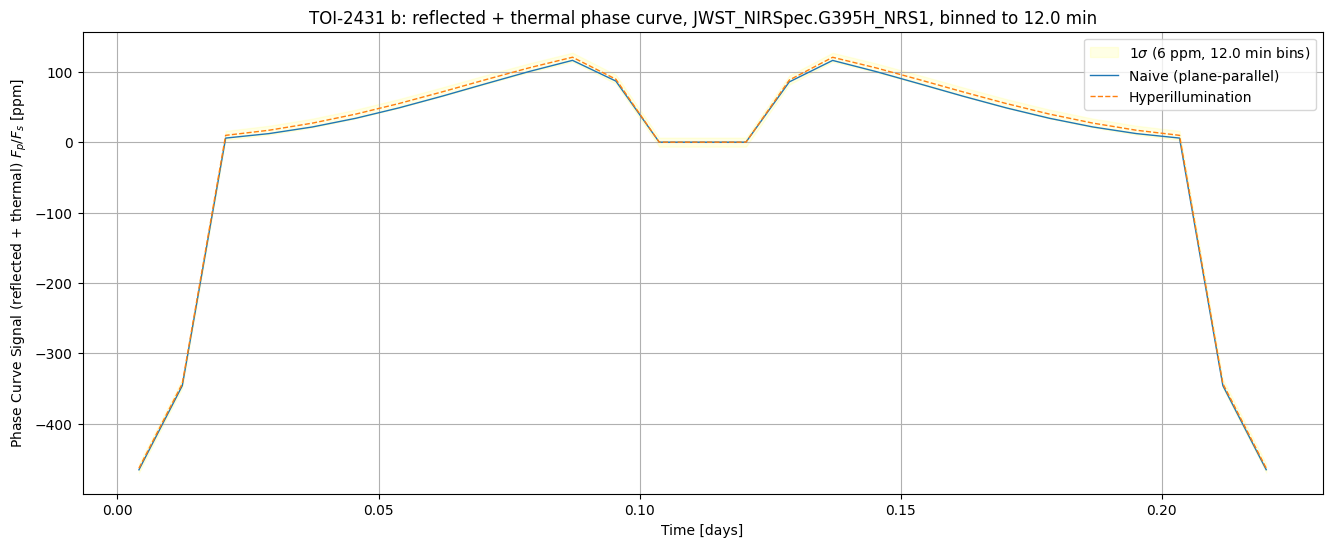

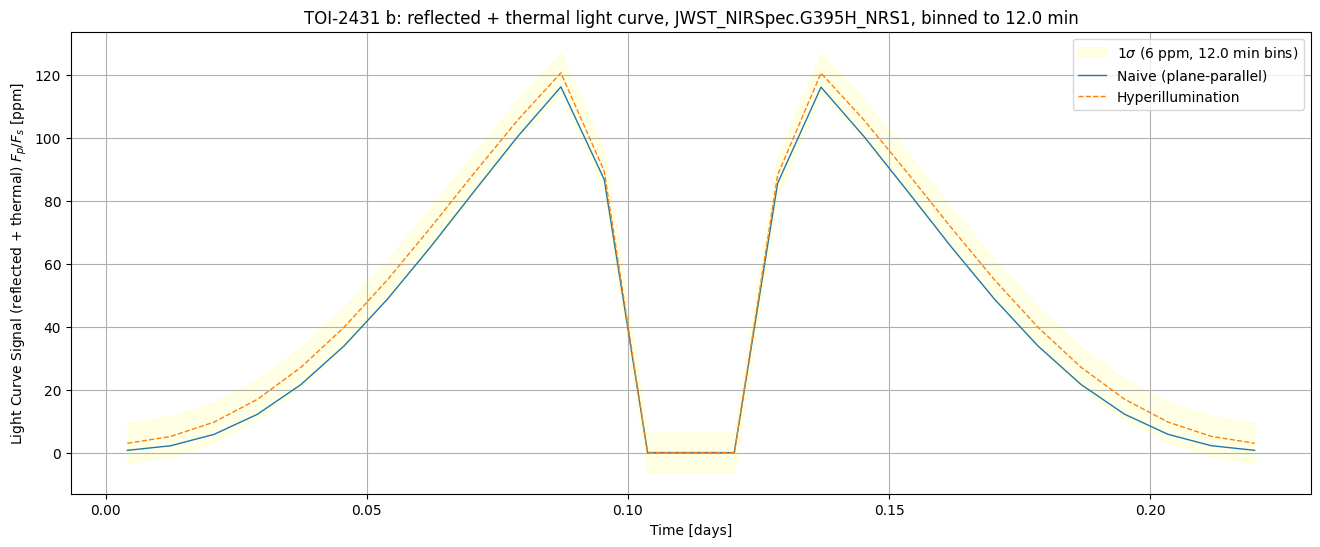

In [7]:
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
plt.show()

tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)

plt.figure(figsize=(16, 6))
plt.fill_between(tb_k, yb_k - sigma_bin, yb_k + sigma_bin, color="yellow", alpha=0.1, label=rf"$1\sigma$ ({sigma_bin:.0f} ppm, {minutes_binning:.1f} min bins)")
plt.plot(tb_n, yb_n, linewidth=1, label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, binned to {minutes_binning:.1f} min")
plt.legend(); plt.grid()
plt.show()

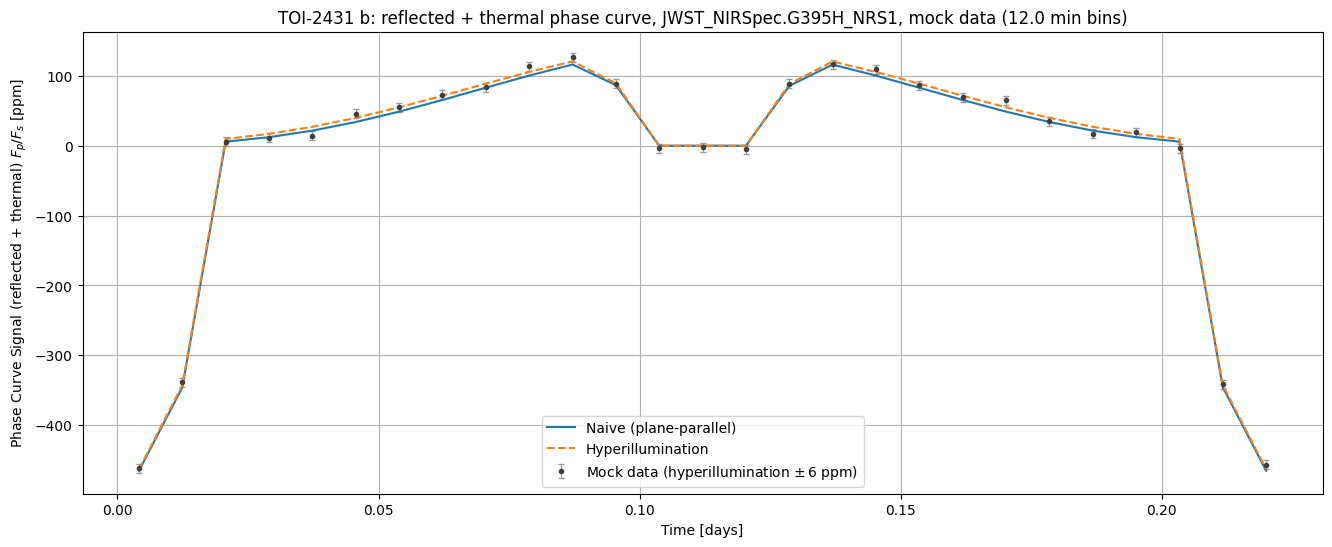

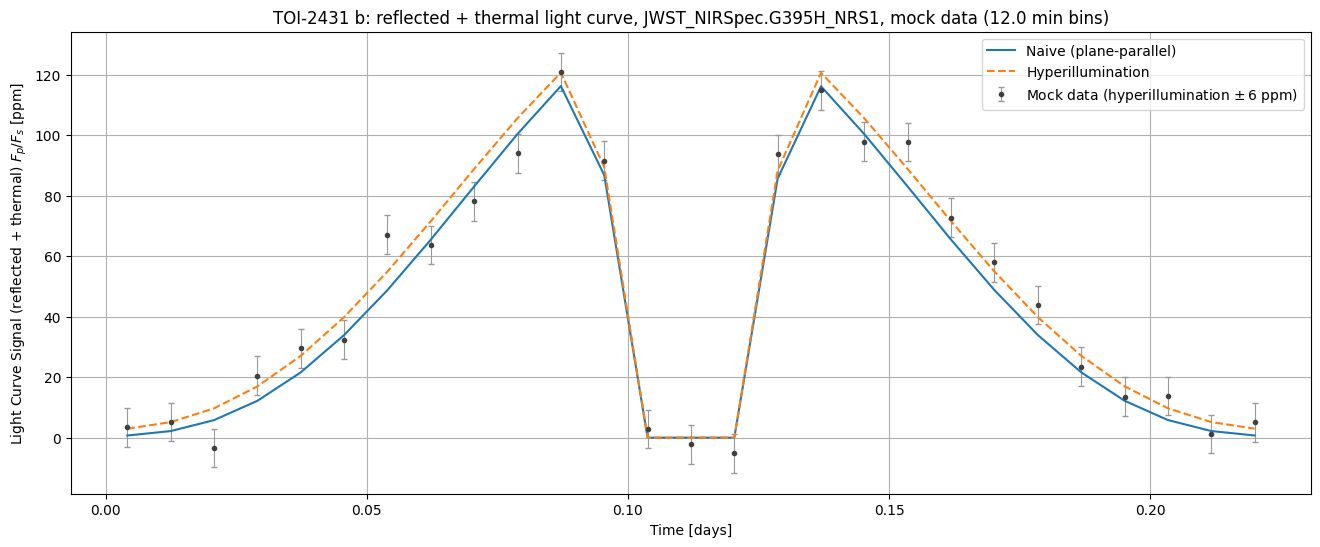

In [8]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(43)   # fixed seed -> reproducible mock data

# --- Phase curve ---
tb_n, yb_n = bin_curve(t_n, (pc_n - 1) * 1e6, minutes_binning)   # naive model, binned [ppm]
tb_k, yb_k = bin_curve(t_k, (pc_k - 1) * 1e6, minutes_binning)   # hyperillumination model, binned [ppm]
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)        # mock data ~ N(hyperillum, sigma_bin)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal phase curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
plt.show()

# --- Light curve ---
tb_n, yb_n = bin_curve(t_n, lc_n * 1e6, minutes_binning)
tb_k, yb_k = bin_curve(t_k, lc_k * 1e6, minutes_binning)
y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)

plt.figure(figsize=(16, 6))
plt.errorbar(tb_k, y_data, yerr=sigma_bin, fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2,
             label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)")
plt.plot(tb_n, yb_n, linewidth=1.5, color="C0", label="Naive (plane-parallel)")
plt.plot(tb_k, yb_k, linewidth=1.5, linestyle="--", color="C1", label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]")
plt.title(f"{planet.name}: reflected + thermal light curve, {instrument}, mock data ({minutes_binning:.1f} min bins)")
plt.legend(); plt.grid()
plt.show()

### 2. Bias in recovered Bond albedo when hyperillumination is neglected - 1-Parameter Fit

In [9]:
# demo: fit the naive model to the hyperillumination truth and report the recovered-A_B bias
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

for free_offset in (True, False):
    A_fit, chi2, rms = fit_naive(cfg, truth, free_offset=free_offset)
    print(f"A_B: {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} "
          f"({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  chi2={chi2:.3f}  "
          f"resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma "
          f"({cfg.n_orbits} orbits, {cfg.n_bins} bins)")

A_B: 0.420 -> 0.394  bias=-0.026 (-6.1%)  chi2=1.858  resid_rms=1.68 ppm  significance=1.36 sigma (3 orbits, 27 bins)
A_B: 0.420 -> 0.353  bias=-0.067 (-16.1%)  chi2=4.640  resid_rms=2.65 ppm  significance=2.15 sigma (3 orbits, 27 bins)


free offset="False" not really meaningful since normalization has error...

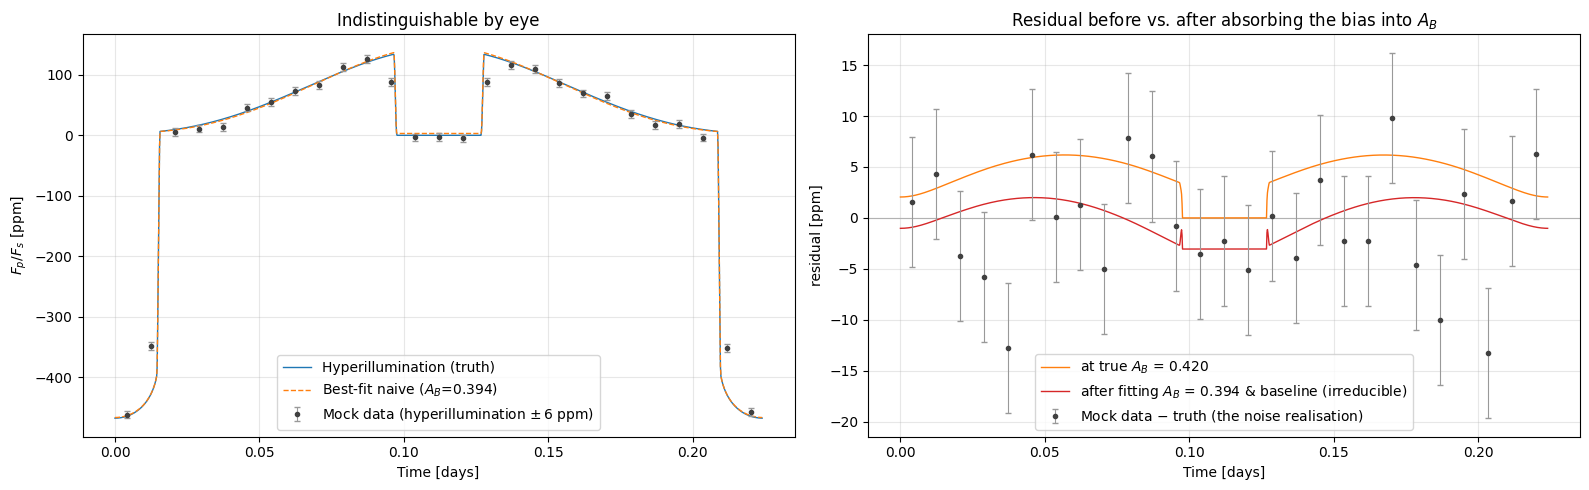

In [10]:
# before vs after absorbing the bias into A_B
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(43).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.
mock_kw = dict(fmt="o", ms=3, color="0.25", ecolor="0.6", elinewidth=.8, capsize=2, zorder=5)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
# left: truth vs best-fit naive
ax[0].errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **mock_kw)
ax[0].plot(t_, truth,   lw=1, label="Hyperillumination (truth)")
ax[0].plot(t_, naive_f, lw=1, ls="--", label=f"Best-fit naive ($A_B$={A_fit:.3f})")
ax[0].set_ylabel(r"$F_p/F_s$ [ppm]"); ax[0].set_xlabel("Time [days]")
ax[0].set_title("Indistinguishable by eye")
# right: both residuals combined on one axes, with the same mock data as the noise the bias has to beat
ax[1].axhline(0., color="0.7", lw=.8, zorder=1)
ax[1].errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **mock_kw)
ax[1].plot(t_, truth - naive_0, lw=1, color="C1", label=rf"at true $A_B$ = {A_B_true:.3f}")
ax[1].plot(t_, truth - naive_f, lw=1, color="C3", label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline (irreducible)")
ax[1].set_ylabel("residual [ppm]"); ax[1].set_xlabel("Time [days]")
ax[1].set_title(r"Residual before vs. after absorbing the bias into $A_B$")
for a_ in ax: a_.grid(alpha=.3); a_.legend()
fig.tight_layout()


### 3. Bias vs. true Bond albedo $A_B$

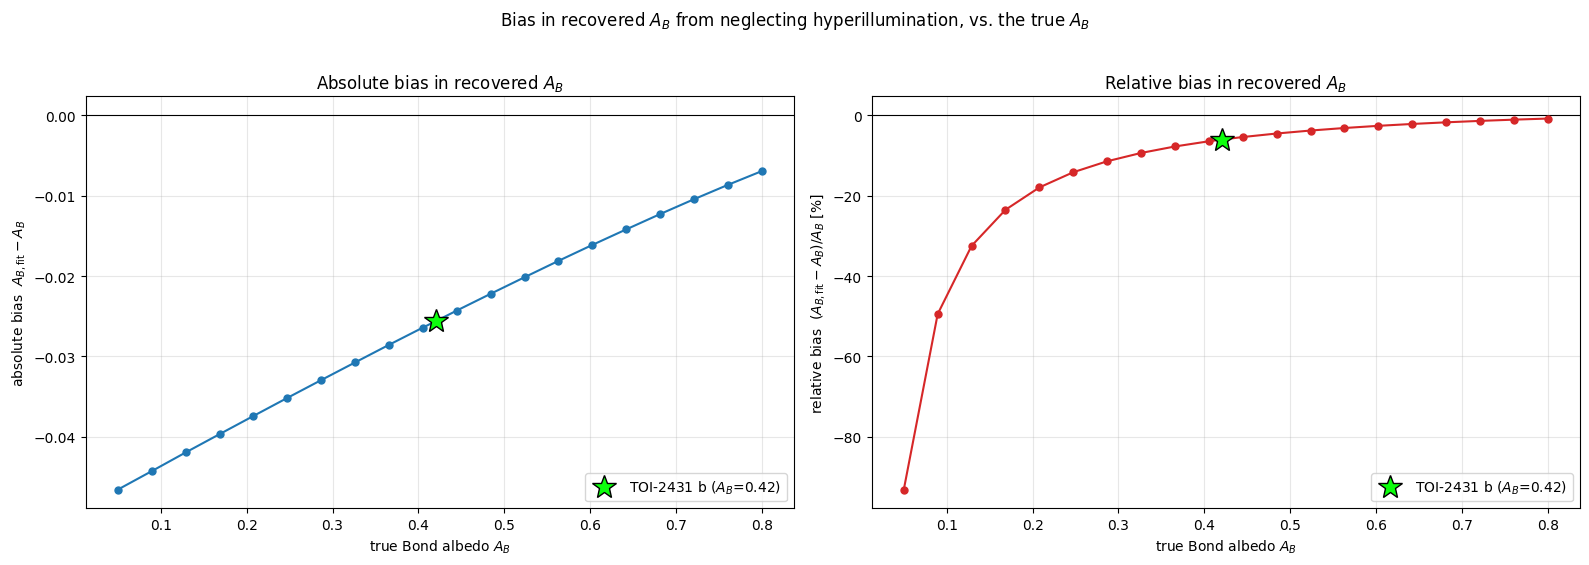

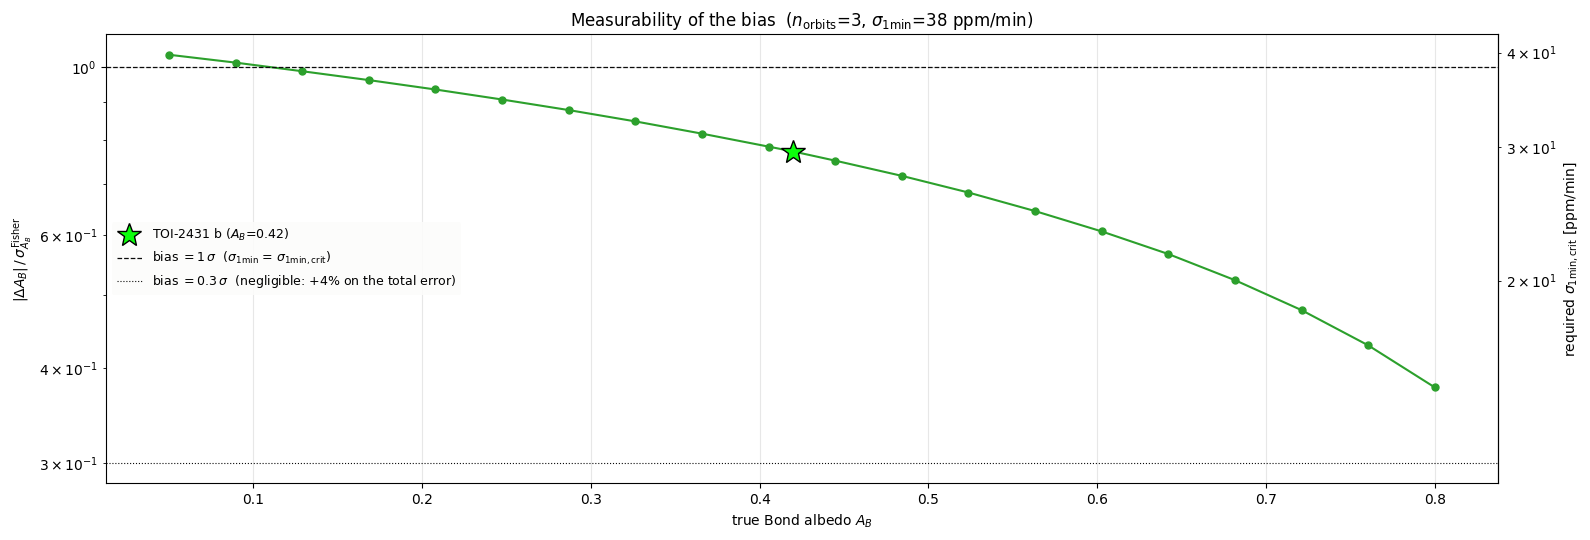

at TOI-2431 b (A_B=0.42): bias -0.0256,  sigma_A_B = 0.0331  ->  |bias|/sigma = 0.77
   sigma_1min = 38.3 ppm/min,  sigma_1min_crit = 29.6 ppm/min  ->  1.3x finer photometry, or 5 orbits instead of 3, before the bias reaches 1 sigma


In [11]:
# Vary the TRUE Bond albedo and refit the naive model at each value (single target geometry,
# free baseline; free_offset=False is not meaningful here -- see 2.). Bias = A_fit - A_B_true.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))

# naive fit at each true A_B (A_fit constrained to physical [0, 1]) plus its Fisher sigma, evaluated at the FIT, where the naive posterior sits
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=False)["naive"]
bias_abs, sigma_fisher = sweep["bias_A_B"], sweep["sigma_A_B"]
bias_rel = 100. * bias_abs / A_B_grid
bias_sigma, sigma_1min_crit = measurability(bias_abs, sigma_fisher, cfg.sigma_1min)   # |bias| in units of sigma_A_B at the CURRENT sigma_1min, and the per-minute precision at which |bias| = sigma_A_B
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))   # absolute | relative
for a_, y, ylab, ttl, col in ((ax[0], bias_abs, r"absolute bias  $A_{B,\rm fit}-A_B$", "Absolute", "C0"),
                              (ax[1], bias_rel, r"relative bias  $(A_{B,\rm fit}-A_B)/A_B$ [%]", "Relative", "C3")):
    a_.axhline(0, color="k", lw=.8)
    a_.plot(A_B_grid, y, "o-", color=col, lw=1.5, ms=5)
    a_.plot(A_B_grid[i0], y[i0], "*", color="#0cff0c", ms=18, mec="k", label=f"{planet.name} ($A_B$={A_B_true:.2f})")
    a_.set_xlabel(r"true Bond albedo $A_B$"); a_.set_ylabel(ylab)
    a_.set_title(ttl + r" bias in recovered $A_B$"); a_.grid(alpha=.3); a_.legend()
fig.suptitle("Bias in recovered $A_B$ from neglecting hyperillumination, vs. the true $A_B$", y=1.02)
fig.tight_layout()
plt.show()

# Is the bias measurable? |bias| / sigma_A_B, with sigma_A_B from the inverted Fisher matrix (offset marginalised, as in the fit).
# The right axis is the SAME curve scaled by cfg.sigma_1min: the per-minute precision at which the bias would be a 1-sigma effect.
# So the dashed horizontal line is where the instrument actually sits - the curve crossing it is the point where hyperillumination stops being ignorable.
fig, a_ = plt.subplots(figsize=(16, 5.5))
measurability_panel(a_, A_B_grid, [(bias_sigma, "o-", "C2", None)], i0, cfg, f"{planet.name} ($A_B$={A_B_true:.2f})",
                    r"$|\Delta A_B|\,/\,\sigma_{A_B}^{\rm Fisher}$",
                    r"Measurability of the bias  ($n_{\rm orbits}$=%d, $\sigma_{1\rm min}$=%.0f ppm/min)" % (cfg.n_orbits, cfg.sigma_1min))
a_.grid(alpha=.3)
fig.tight_layout()
plt.show()

fac = cfg.sigma_1min / sigma_1min_crit[i0]   # how much finer the photometry must get before the bias is a 1-sigma effect
print(f"at {planet.name} (A_B={A_B_true:.2f}): bias {bias_abs[i0]:+.4f},  sigma_A_B = {sigma_fisher[i0]:.4f}  ->  |bias|/sigma = {bias_sigma[i0]:.2f}")
print(f"   sigma_1min = {cfg.sigma_1min:.1f} ppm/min,  sigma_1min_crit = {sigma_1min_crit[i0]:.1f} ppm/min"
      f"  ->  {fac:.1f}x finer photometry, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits}, before the bias reaches 1 sigma")


At low true $A_B$ the best-fit naive albedo rails at the physical floor $A_{B,\rm fit}=0$ (the naive model is driven to zero albedo), so the absolute bias saturates at $-A_B$ and the relative bias at $-100\%$. The bias is negative throughout and its magnitude shrinks as $A_B\to1$.

### 4. In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

TODO: For careful evaluation of physical parameter space, add Roche limit to map

Theoretically the period P should be varied with (a/R★) for a fixed ρ★ = 3π(a/R★)³/(GP²). This is not necessary/answer-changing since the period is degenerate in the bias analysis.

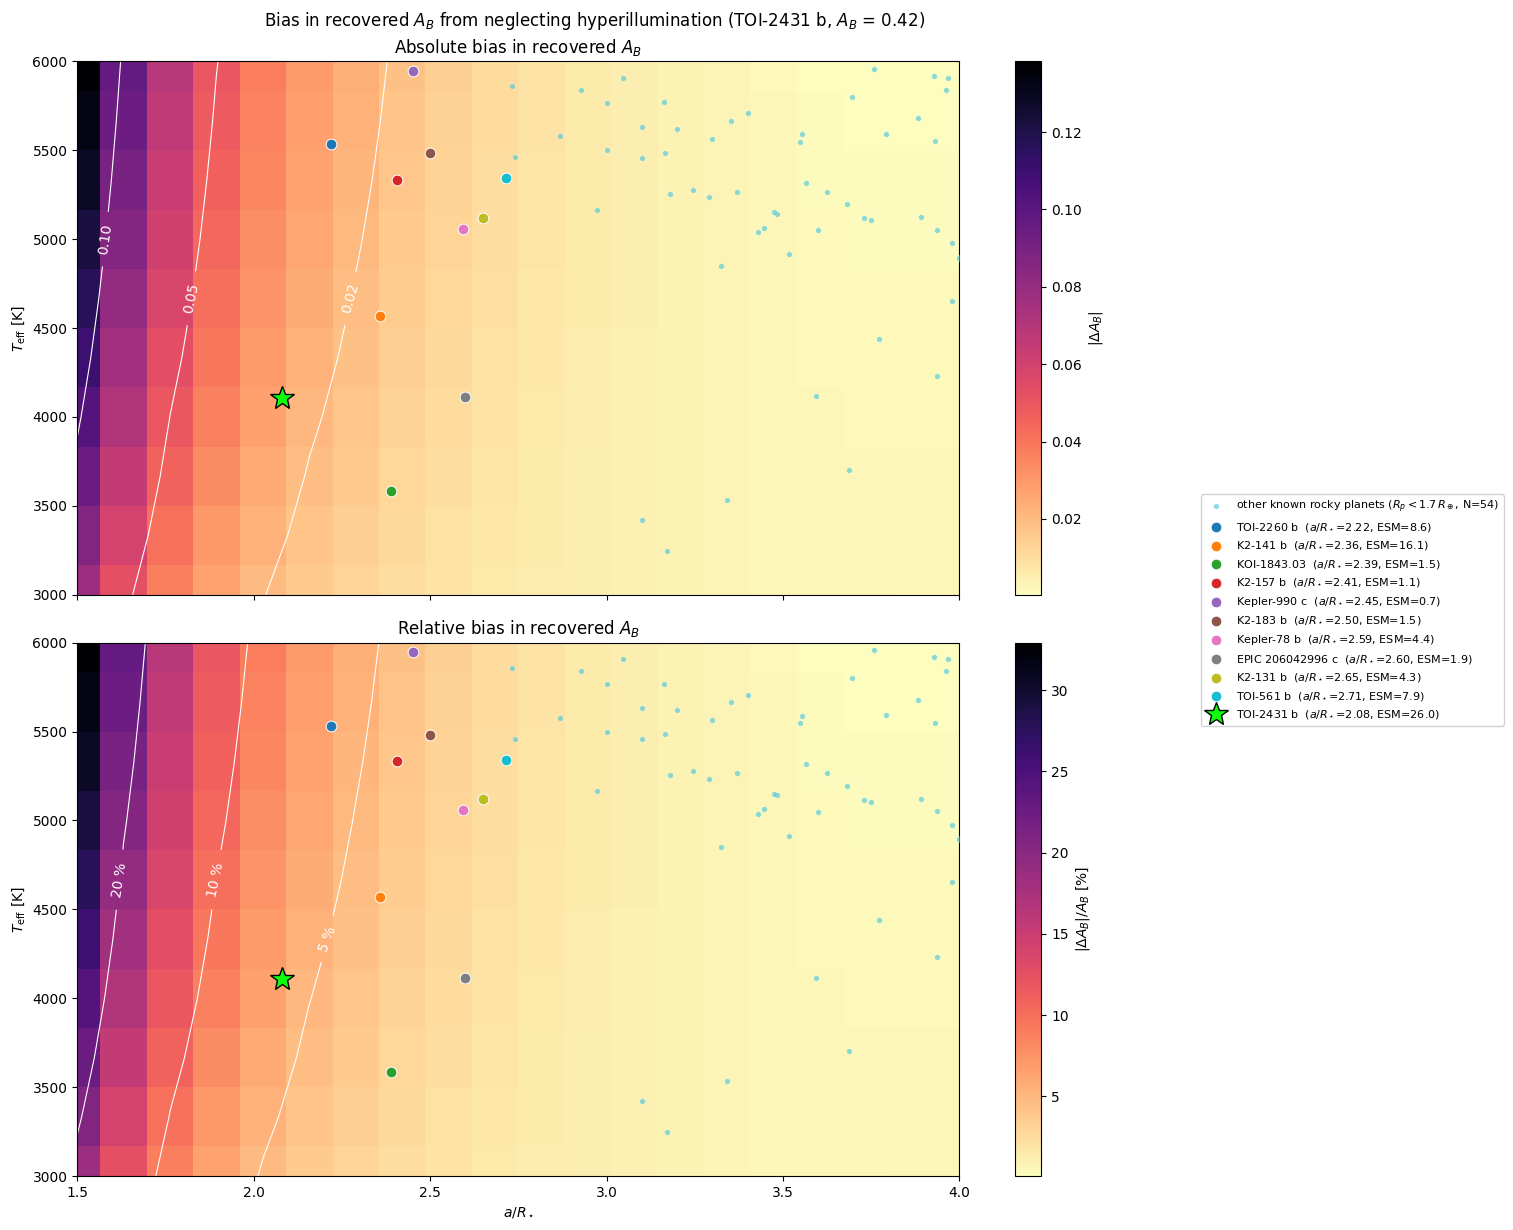

In [12]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma and of the target's brightness. The (a/Rs, T_eff) cells are independent -> run them in parallel (processes; joblib).
a_rs_grid  = np.linspace(1.5, 4.0, 20)
T_eff_grid = np.linspace(3000., 6000., 10)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, A_B_true, a_rs=ar, T_s=Ts, **kw) for Ts in T_eff_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(T_eff_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run

# Plotting: the absolute bias |Delta A_B| (top) and the relative bias |Delta A_B|/A_B (bottom) on the same grid. Also used for 5.
def plot_bias_maps(xg, yg, bias_map, ykey, ylabel):
    fig, axs = plt.subplots(2, 1, figsize=(12, 12.5), sharex=True)
    for ax, z, levels, fmt, clabel, title in ((axs[0], np.abs(bias_map), [0.02, 0.05, 0.10], "%.2f", r"$|\Delta A_B|$", r"Absolute bias in recovered $A_B$"),
                                              (axs[1], 100. * np.abs(bias_map) / A_B_true, [5, 10, 20, 40], "%g %%", r"$|\Delta A_B|/A_B$ [%]", r"Relative bias in recovered $A_B$")):
        z = np.ma.masked_invalid(z)
        im = ax.pcolormesh(xg, yg, z, cmap="magma_r", shading="auto")
        cs = ax.contour(xg, yg, z, levels=levels, colors="w", linewidths=.8)
        ax.clabel(cs, fmt=fmt)
        # known ROCKY planets (NASA Exoplanet Archive, Rp < 1.7 R_Earth), labelled with a/Rs and ESM.
        # target=planet draws the notebook's planet as the green star (name, a/Rs, ESM read off PlanetParams) and keeps it out of the archive scatter.
        overlay_planets(AGG, ax, ykey, (yg[0], yg[-1]), a_rs_lim=(xg[0], xg[-1]), target=planet)
        ax.set_facecolor("0.85")   # railed cells show as grey = "naive model breaks down"
        ax.set_xlim(xg[0], xg[-1]); ax.set_ylim(yg[0], yg[-1])
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        fig.colorbar(im, ax=ax, label=clabel)
    axs[-1].set_xlabel(r"$a/R_\star$")
    fig.suptitle(rf"Bias in recovered $A_B$ from neglecting hyperillumination ({planet.name}, $A_B$ = {A_B_true:.2f})")
    fig.tight_layout()
    fig.legend(*axs[0].get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, framealpha=.9)
    plt.show()

plot_bias_maps(a_rs_grid, T_eff_grid, bias_map, "st_teff", r"$T_{\rm eff}$ [K]")

### 5. In which regimes does hyperillumination matter? Bias map over (a/Rs, Rp/Rs)

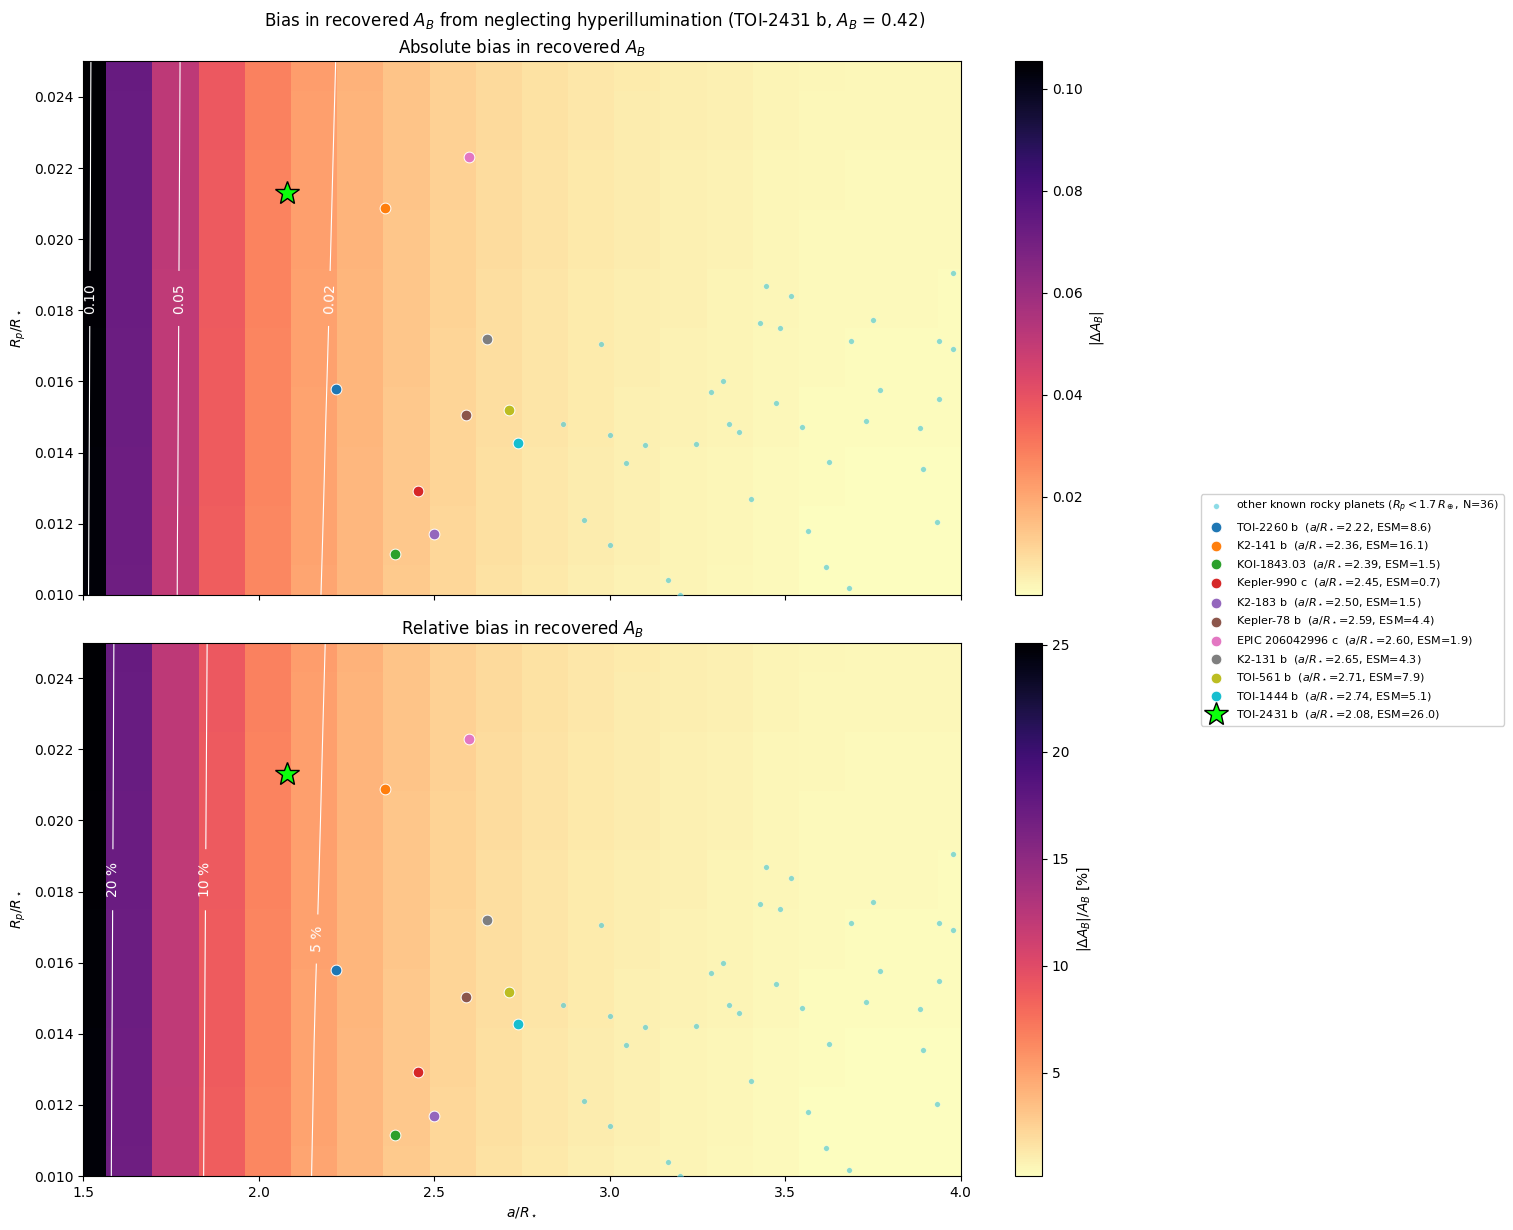

In [13]:
# Grid box, widened by map_grid where the target itself falls outside it, so the notebook's own `planet` is always on its own map.
a_rs_grid  = map_grid(1.5, 4.0, 20, include=planet.R / planet.r2)
rp_rs_grid = map_grid(0.01, 0.025, 10, include=planet.r1 / planet.r2)
kw = dict(n_layers=40, n_lo=300, n_la=150)     # the 200 K T_floor in model_pcurve keeps the naive terminator spline stable at this resolution

flat = Parallel(n_jobs=-1, backend="loky")(
    delayed(bias_cell)(cfg, A_B_true, a_rs=ar, rp_rs=rpp, **kw) for rpp in rp_rs_grid for ar in a_rs_grid)
bias_map = np.array(flat).reshape(len(rp_rs_grid), len(a_rs_grid))
get_reusable_executor().shutdown(wait=True)  # free memory SPIDERMAN leaks in the workers before the next run


# Plotting (plot_bias_maps from 4.): absolute (top) and relative (bottom) bias
plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, "pl_ratror", r"$R_p/R_\star$")


Bias is negative throughout the map.

### 6. Per-planet decision: does hyperillumination matter for the closest-in rocky planets?

The 10 smallest-$a/R_\star$ rocky planets of the map in 5., each re-fitted with its **own** geometry and its **own** PandExo noise for this instrument, at the same assumed $A_B$.
The bias is noise-independent (it is a pure model-degeneracy quantity), so only the Fisher $\sigma_{A_B}$ moves with the noise and
$\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|\Delta A_B|/\sigma_{A_B}$ is an identity, not an extrapolation: the per-minute precision at which the bias would be a $1\sigma$ effect.
A planet needs hyperillumination exactly where the delivered $\sigma_{1\rm min}$ is at or below the required $\sigma_{1\rm min, crit}$.

A planet whose Fisher $\sigma_{A_B}$ is at or above the flat-prior std $(hi - lo)/\sqrt{12}$ of the fit bounds (0.289 for $A_B \in [0, 1]$, dashed line) is marked *unconstrained* (hatched bars): there $|\Delta A_B|/\sigma_{A_B}$ is a ratio to a meaningless number, so neither "needs hyperillumination" nor "naive OK" applies.


Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation


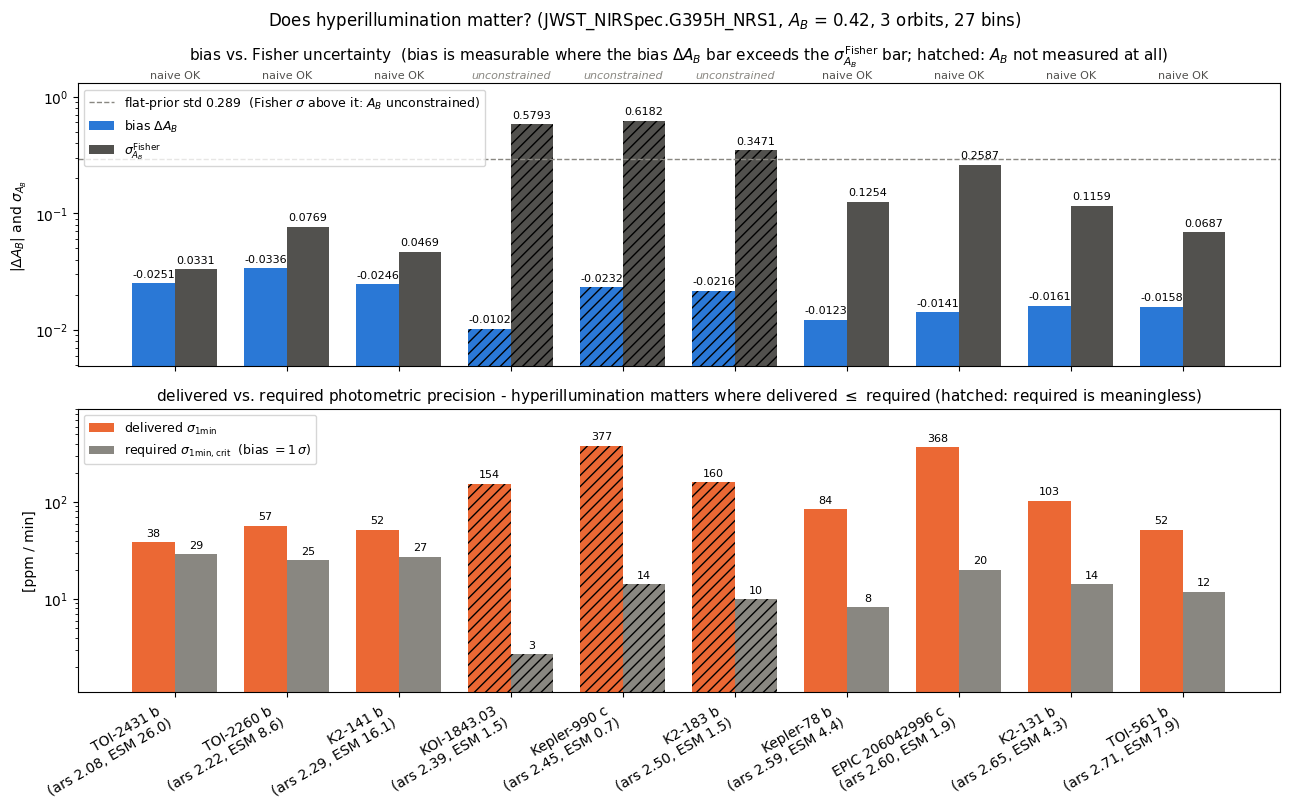

0 of 10 needs hyperillum: -
7 of 10 naive OK: TOI-2431 b, TOI-2260 b, K2-141 b, Kepler-78 b, EPIC 206042996 c, K2-131 b, TOI-561 b
3 of 10 unconstrained: KOI-1843.03, Kepler-990 c, K2-183 b
            name  a_rs    esm     bias   sigma  bias_sigma  sigma_1min  sigma_1min_crit       verdict
      TOI-2431 b 2.081  25.96  -0.0251 0.03311      0.7581       38.29            29.03      naive OK
      TOI-2260 b 2.219  8.632 -0.03359 0.07689      0.4368       57.16            24.97      naive OK
        K2-141 b 2.292  16.12 -0.02463 0.04688      0.5253       51.71            27.17      naive OK
     KOI-1843.03 2.389   1.47 -0.01018  0.5793     0.01757       154.1            2.708 unconstrained
    Kepler-990 c 2.453 0.6968 -0.02318  0.6182     0.03751       377.3            14.15 unconstrained
        K2-183 b   2.5  1.483 -0.02161  0.3471     0.06226       159.6            9.936 unconstrained
     Kepler-78 b 2.592  4.415 -0.01227  0.1254      0.0978       84.04            8.219      nai

In [14]:
# Same sample definition overlay_planets draws on the maps (rocky, Rp < 1.7 R_Earth, inside the map box), so figure and map cannot disagree.
# The target is NOT excluded here: this figure compares it against its neighbours instead of marking it separately.
top10 = rocky_sample(AGG, "pl_ratror", (rp_rs_grid[0], rp_rs_grid[-1]), a_rs_lim=(a_rs_grid[0], a_rs_grid[-1])).nsmallest(10, "a_over_r2")
planets10 = hi_planets_by_name(list(top10.pl_name))

# One PandExo run per planet: NOT cached and seconds per target, so keep this dict rather than recomputing it.
sigma10 = rms_1min_sample(top10.pl_name, instrument, instrument_pandexo)

tab_AB = planet_bias_table(cfg, A_B_true, planets10, sigma10, AGG=AGG, **kw)   # cfg supplies filter / stellar grid / albedo model / n_bins / n_orbits; geometry and sigma_1min are per planet; AGG only supplies the ESM for the tick labels
fig, ax = plot_planet_bias_bars(tab_AB, log_bias=True, title=f"Does hyperillumination matter? ({instrument}, $A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits, {cfg.n_bins} bins)")   # log_bias: an unconstrained sigma (~0.6) would otherwise flatten the measurable ones (~0.03)
plt.show()

# Three-way verdict (bias_verdict): bias >= 1 sigma needs hyperillumination; below it naive is OK only where sigma_A_B is below the flat-prior std of the fit bounds, otherwise A_B is simply unconstrained.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED):
    sel = tab_AB[tab_AB.verdict == v]
    print(f"{len(sel)} of {len(tab_AB)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_AB[["name", "a_rs", "esm", "bias", "sigma", "bias_sigma", "sigma_1min", "sigma_1min_crit", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
